# Evaluation: which strawberry model should we trust?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/03_Evaluation/notebooks/TD2_strawberry_student.ipynb)

In TD1 (Foundations), you used eight infrared features to predict Strawberry
or NON-Strawberry. Here we compare a small tree, a deep tree and a random
forest, then add a small convolutional neural network (CNN). Does a
better training result also mean better predictions?

Section 1 is a quick recap. Run its four setup cells, then focus on the new
training–validation–test split in section 2. All code is supplied; answer
the interpretation questions in the Your answer text cells.

## 1. Quick recap and setup

We reuse the same fruit-purée data, targets and preparation as TD1:
exclude the two conflicting records and turn each spectrum into
eight window means (B1–B8). Strawberry and NON-Strawberry remain
the two classes. The code below prepares these familiar inputs.

Install the neural-network tools and load the tools for tables, plots
and models. All code is provided.

In [1]:
%pip -q install "jax[cpu]==0.11.2" keras==3.15.1
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
import numpy as np
from sklearn.preprocessing import StandardScaler

Read the same fixed data file, separate the targets, and arrange
the measured spectra with one sample per row, as in TD1.

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/zwbben/SpectroscopyData/"
    "4db9b8168fac1185973d1e7888d51f7f33f94857/MIR_Fruit_purees.csv"
)
raw_data = pd.read_csv(DATA_URL, header=None)
targets = raw_data.iloc[0, 1:]
numeric_data = raw_data.iloc[1:].astype(float)
spectra = numeric_data.iloc[:, 1:].T
spectra.columns = numeric_data.iloc[:, 0]

Leave out the same two identically measured records with conflicting targets. This keeps the same 981 samples as TD1.

In [3]:
repeated = spectra.duplicated(keep=False)
spectra = spectra.loc[~repeated]
targets = targets.loc[~repeated]

Calculate the same eight window means. The table is a reminder of
the inputs for the three tree models. The CNN later uses the full
spectra, so we can discuss both the model and its input representation.

`round(4)` displays four digits after the decimal point: for example,
0.123456 becomes 0.1235. The calculations keep the full precision.

In [4]:
features = pd.DataFrame(index=spectra.index)
features["B1"] = spectra.loc[:, 899:1012].mean(axis=1)
features["B2"] = spectra.loc[:, 1012:1125].mean(axis=1)
features["B3"] = spectra.loc[:, 1125:1238].mean(axis=1)
features["B4"] = spectra.loc[:, 1238:1351].mean(axis=1)
features["B5"] = spectra.loc[:, 1351:1464].mean(axis=1)
features["B6"] = spectra.loc[:, 1464:1577].mean(axis=1)
features["B7"] = spectra.loc[:, 1577:1690].mean(axis=1)
features["B8"] = spectra.loc[:, 1690:1803].mean(axis=1)
features.head().round(4)

,B1,B2,B3,B4,B5,B6,B7,B8
1,0.0035,0.0097,0.0052,0.0051,0.0049,0.0019,0.0020,0.0019
2,0.0046,0.0149,0.0052,0.0043,0.0047,0.0006,-0.0003,0.0002
3,0.0041,0.0098,0.0050,0.0048,0.0047,0.0019,0.0022,0.0017
4,0.0037,0.0107,0.0055,0.0052,0.0045,0.0009,0.0015,0.0022
5,0.0038,0.0104,0.0057,0.0053,0.0044,0.0008,0.0012,0.0024


## 2. Give three sets of samples different jobs

- Training: teach each model.
- Validation: compare models and choose one.
- Test: check the chosen model after the choice is fixed.

Keep TD1's 197 test samples aside. Divide its original 784 training samples
into 588 training and 196 validation samples. Every model uses exactly the
same groups, giving about 60% training, 20% validation and 20% test samples.
The small tree now learns from fewer examples than in TD1, so its results
can change.

The code first repeats TD1's split, then sets aside a quarter of the original
training group for validation. `X_development` and `y_development` hold that
original group before it is divided.

In [5]:
X_development, X_test, y_development, y_test = train_test_split(
    features, targets, test_size=0.20, random_state=42, stratify=targets
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development, y_development, test_size=0.25,
    random_state=42, stratify=y_development
)
print("Training:", len(X_train))
print("Validation:", len(X_validation))
print("Test:", len(X_test))

Training: 588
Validation: 196
Test: 197


The test group is the same one used in Foundations. We keep it out of model
comparison here, but its reuse is a classroom exercise rather than new
independent evidence. The file also lacks IDs for physical specimens and batches.

### Stop and explain 1

Which samples teach the models, which help us choose, and which are used
at the end? Why should all models use the same training and validation samples?

Your answer:

Write your answer here in words.

## 3. Compare a small and a deep tree

Start with a tree that asks at most two questions along a path. `fit`
learns from the training data. For these classifiers, `score` gives
accuracy on the named data: the fraction of predictions matching the targets.
The two scores below answer different questions: how well does it fit the
training examples, and how well does it predict validation examples?

An accuracy of 0.90 means that 90% of the samples were classified correctly.

Displayed scores are rounded to three decimal places: for example,
0.87654 is shown as 0.877. This changes the display, not the score used.

In [6]:
small_tree = DecisionTreeClassifier(max_depth=2, random_state=42)
small_tree.fit(X_train, y_train)
small_training = small_tree.score(X_train, y_train)
small_validation = small_tree.score(X_validation, y_validation)
print("Small tree, training:", round(small_training, 3))
print("Small tree, validation:", round(small_validation, 3))

Small tree, training: 0.838
Small tree, validation: 0.827


Now remove the depth limit. The deep tree can keep adding questions to
separate training examples. Only the model's complexity changes; the
measurements, targets and sample groups stay the same.

Overfitting means learning details that help on the training samples
but do not help as much on other samples. A growing gap between
training and validation accuracy is a warning sign.

In [7]:
deep_tree = DecisionTreeClassifier(random_state=42)
deep_tree.fit(X_train, y_train)
deep_training = deep_tree.score(X_train, y_train)
deep_validation = deep_tree.score(X_validation, y_validation)
print("Deep tree, training:", round(deep_training, 3))
print("Deep tree, validation:", round(deep_validation, 3))

Deep tree, training: 1.0
Deep tree, validation: 0.842


### Stop and explain 2

How much does training accuracy improve when the tree becomes deeper?
Does validation accuracy improve by as much? Explain what this suggests
about overfitting.

Your answer:

Write your answer here in words.

## 4. Add a random forest

Imagine asking 100 different sorting trees about the same sample.
Each tree learns from a different random collection of training
examples: some examples can be drawn more than once, while others
are left out of that tree. At each decision, the tree considers a
random selection of features and learns a useful cut-off among them.
This gives the trees different sorting routes.

A new sample follows a route through every tree. Each final group
gives an estimate of support for each class. The forest averages
those estimates and predicts the class with the greater support.
A final group containing mostly Strawberry training samples gives more
support to Strawberry.

For illustration, suppose three trees give these estimates for one sample:

| Tree | Estimated support for Strawberry |
|---|---|
| 1 | 80% |
| 2 | 60% |
| 3 | 40% |
| Average | 60% |

Together they predict Strawberry. The 60% describes estimated support
for this one sample; validation accuracy describes how often the
forest is correct across many examples with known targets.

One tree's poor decision has less influence when the other trees
make different mistakes. Making 100 identical copies of one tree
would repeat its mistakes. Combining varied trees can help, but we
still need validation to check whether it helps on our data.

The code builds 100 trees, fits them, and checks the same training
and validation groups used by the other models.

In [8]:
forest = RandomForestClassifier(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)
forest_training = forest.score(X_train, y_train)
forest_validation = forest.score(X_validation, y_validation)
print("Forest, training:", round(forest_training, 3))
print("Forest, validation:", round(forest_validation, 3))

Forest, training: 1.0
Forest, validation: 0.898


## 5. Add a small convolutional neural network

A spectrum is an ordered line of measurements. Nearby wavenumbers can
form a local pattern, such as a rising edge or a peak. A one-dimensional
convolutional neural network (1D CNN) learns small pattern detectors and
slides each one along the spectrum, checking neighbouring signals together.

Our CNN receives all 235 signals in their original order. The three tree
models receive eight window means. They use the same training, validation
and test samples, but different amounts of spectral detail. A score
difference therefore reflects both the model and its input representation.

The shaded region below contains five neighbouring signals: the width
seen by one pattern detector at a time. During training, the network
learns which local patterns help distinguish the targets. We do not
assign chemical identities to the learned patterns in this exercise.

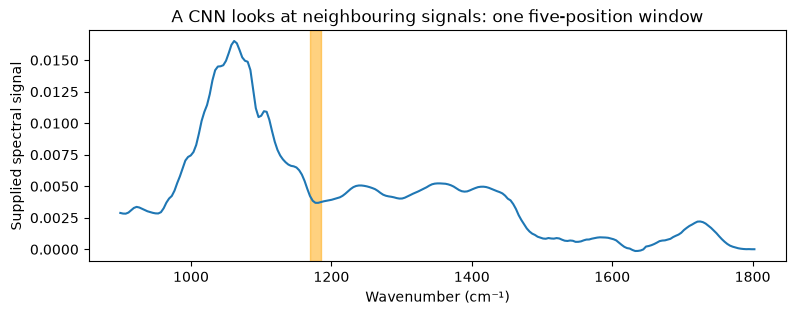

In [9]:
example_spectrum = spectra.loc[X_train.index[0]]
plt.figure(figsize=(9, 3))
plt.plot(spectra.columns, example_spectrum)
plt.axvspan(spectra.columns[70], spectra.columns[74], color="orange", alpha=0.5)
plt.xlabel("Wavenumber (cm⁻¹)")
plt.ylabel("Supplied spectral signal")
plt.title("A CNN looks at neighbouring signals: one five-position window")
plt.show()

Load the network tools and set repeatable starting values. These lines
prepare the calculation; the model structure appears below.

In [10]:
import os
os.environ["KERAS_BACKEND"] = "jax"
import keras
keras.utils.set_random_seed(42)

Put each measured position on a comparable numerical scale, as with the
neural network in TD1. The scaler learns averages and spreads from
training spectra only, then applies them to validation and test spectra.
The row selections keep exactly the same sample groups as the trees.

In [11]:
spectrum_scaler = StandardScaler()
cnn_train = spectrum_scaler.fit_transform(spectra.loc[X_train.index]).astype("float32")
cnn_validation_data = spectrum_scaler.transform(spectra.loc[X_validation.index]).astype("float32")
cnn_test = spectrum_scaler.transform(spectra.loc[X_test.index]).astype("float32")

Add a dimension to say there is one signal at each of the 235 positions.
The CNN also needs numerical targets: Strawberry becomes 1 and
NON-Strawberry becomes 0. These are the same recorded classes as before.
`-1` lets the program fill in the number of samples; the other two sizes
mean 235 positions and one signal per position.

In [12]:
cnn_train = cnn_train.reshape(-1, 235, 1)
cnn_validation_data = cnn_validation_data.reshape(-1, 235, 1)
cnn_test = cnn_test.reshape(-1, 235, 1)
cnn_y_train = y_train.eq("Strawberry").astype("float32").to_numpy()
cnn_y_validation = y_validation.eq("Strawberry").astype("float32").to_numpy()
print("CNN training input:", cnn_train.shape)

CNN training input: (588, 235, 1)


Read this small network from top to bottom:

| Step | Job |
|---|---|
| Input | Receive 235 positions, one signal at each |
| Conv1D | Learn eight pattern detectors, each looking at five neighbouring signals |
| MaxPooling1D | Keep the strongest response within groups of four nearby positions |
| Flatten | Place those responses in one list |
| Dense | Combine the responses into a Strawberry score between 0 and 1 |

The eight detectors are learned patterns, rather than our eight fixed
spectral windows. The final score is used to choose a class; it is not
a strawberry concentration or a guarantee of correctness.

In [13]:
cnn = keras.Sequential([
    keras.Input(shape=(235, 1)),
    keras.layers.Conv1D(8, 5, activation="relu"),
    keras.layers.MaxPooling1D(4),
    keras.layers.Flatten(),
    keras.layers.Dense(1, activation="sigmoid")
])

Train for 30 passes through the training spectra. The training method
adjusts the pattern detectors and how their responses are combined.
Only training targets enter `fit`. Afterwards, check training and
validation accuracy, just as for the trees. All settings are supplied.
`compile` selects the learning method and an error measure for two classes.
`evaluate` returns that error followed by accuracy; `[1]` selects accuracy.

In [14]:
cnn.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history = cnn.fit(cnn_train, cnn_y_train, epochs=30, batch_size=32, verbose=0)
cnn_training = cnn.evaluate(cnn_train, cnn_y_train, verbose=0)[1]
cnn_validation = cnn.evaluate(cnn_validation_data, cnn_y_validation, verbose=0)[1]
print("CNN, training:", round(cnn_training, 3))
print("CNN, validation:", round(cnn_validation, 3))

CNN, training: 0.961
CNN, validation: 0.954


### Stop and explain 3

What does the CNN look at together when its small window moves along
the spectrum? Why can we not attribute a difference from the forest
entirely to the model type? Why does only training data set the scaling?

Your answer:

Write your answer here in words.

Put all four pairs of scores in one table. The Input column reminds us
that the CNN uses more spectral detail. Compare validation accuracy on
the same samples, alongside each model's training/validation gap.

In [15]:
results = pd.DataFrame({
    "Model": ["Small tree", "Deep tree", "Forest", "1D CNN"],
    "Input": ["8 window means", "8 window means", "8 window means", "235 signals"],
    "Training": [small_training, deep_training, forest_training, cnn_training],
    "Validation": [small_validation, deep_validation, forest_validation, cnn_validation]
})
results = results.set_index("Model")
results.round(3)

,Input,Training,Validation
Model,,,
Small tree,8 window means,0.838,0.827
Deep tree,8 window means,1.000,0.842
Forest,8 window means,1.000,0.898
1D CNN,235 signals,0.961,0.954


The bars show the same numbers. A large gap between a model's training and
validation bars is a warning. Also compare with a simple rule that always
predicts NON-Strawberry, the most common training class.

A forest can also fit its training samples very closely. Its validation
accuracy still needs to be checked; combining trees does not remove that need.

In the comparison rule, `==` checks whether a target matches NON-Strawberry;
`mean()` gives the fraction of matching targets.

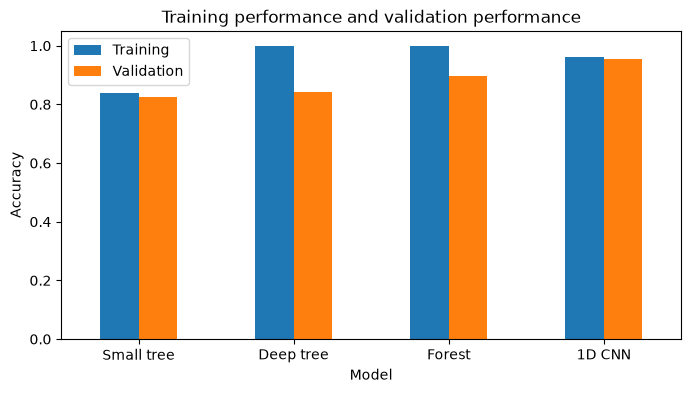

Always NON-Strawberry, validation: 0.643


In [16]:
results.plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.title("Training performance and validation performance")
plt.show()
baseline_validation = (y_validation == "NON-Strawberry").mean()
print("Always NON-Strawberry, validation:", round(baseline_validation, 3))

### Stop and explain 4

Which model has the highest validation accuracy? Does it beat the constant
NON-Strawberry rule? Explain why the training score alone cannot choose the winner.
Why are varied trees more useful than 100 identical copies of one tree?

Your answer:

Write your answer here in words.

## 6. Choose first, then test

Choose the model with the highest validation accuracy. `idxmax` returns
the name beside the largest validation number. The first line links each
name to its trained model; `models[chosen_name]` retrieves that model.
No model is retrained here.

In [17]:
models = {"Small tree": small_tree, "Deep tree": deep_tree, "Forest": forest, "1D CNN": cnn}
chosen_name = results["Validation"].idxmax()
chosen_model = models[chosen_name]
print("Chosen using validation samples:", chosen_name)

Chosen using validation samples: 1D CNN


Apply the fixed choice to the test samples. The CNN receives full scaled
spectra and assigns Strawberry when its score is at least 0.5. A chosen
tree receives the eight window means. The `if` chooses the appropriate
input for the selected model. Keep that model choice fixed after testing.

In [18]:
if chosen_name == "1D CNN":
    cnn_scores = cnn.predict(cnn_test, verbose=0).ravel()
    predictions = np.where(cnn_scores >= 0.5, "Strawberry", "NON-Strawberry")
else:
    predictions = chosen_model.predict(X_test)

Check the predictions against the recorded test targets. In the confusion
matrix, rows are targets and columns are predictions. NON-Strawberry
predicted Strawberry is a false acceptance; the opposite is a false
rejection. The diagonal contains correct predictions.

Test accuracy: 0.97


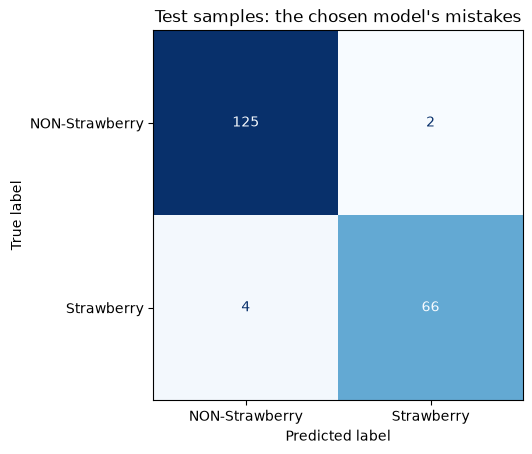

In [19]:
test_accuracy = accuracy_score(y_test, predictions)
print("Test accuracy:", round(test_accuracy, 3))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=["NON-Strawberry", "Strawberry"],
    cmap="Blues", colorbar=False
)
plt.title("Test samples: the chosen model's mistakes")
plt.show()

### Stop and explain 5

How many false acceptances and false rejections occurred? Why would it be
misleading to try different settings now and report only the best test score?

Your answer:

Write your answer here in words.

## 7. See what happens as a tree gets deeper

The model choice and its test check above are finished. Now use a
training/test curve to illustrate overfitting. Each tree below learns
from the same 588 training samples, with a different maximum depth.
A deeper tree can divide the training examples into smaller groups.

The loop repeats the same fit-and-check steps for depths 1 to 12 and
records both accuracies. All code is supplied; focus on the two curves.
These trees use the eight window means, as before.

In [20]:
depths = range(1, 13)
depth_training = []
depth_test = []
for depth in depths:
    depth_tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    depth_tree.fit(X_train, y_train)
    depth_training.append(depth_tree.score(X_train, y_train))
    depth_test.append(depth_tree.score(X_test, y_test))

Follow the training line and test line separately. Greater training
accuracy can coexist with little improvement, or deterioration, on
excluded examples. A widening gap is a warning about overfitting.

This test curve is a classroom illustration after model selection.
Choosing a new depth from its highest point would use test outcomes for
selection. A further independent test would then be needed. In a model
development exercise, choose depth using validation results.

The vertical axis is zoomed to 0.65–1.00 so the differences are easier
to see. Read the accuracy values as well as the distance between the lines.

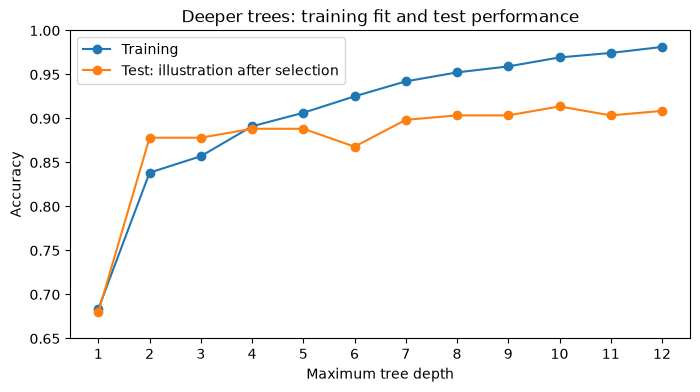

In [21]:
plt.figure(figsize=(8, 4))
plt.plot(depths, depth_training, marker="o", label="Training")
plt.plot(depths, depth_test, marker="o", label="Test: illustration after selection")
plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.xticks(depths)
plt.ylim(0.65, 1.00)
plt.title("Deeper trees: training fit and test performance")
plt.legend()
plt.show()

### Stop and explain 6

Do the training and test accuracies improve together as depth increases?
Use the gap to explain overfitting. If we now chose a depth from the
best test point, what would we need for an independent final check?

Your answer:

Write your answer here in words.

## 8. Explain the comparison

Training teaches a model; validation helps choose between models;
testing checks the fixed choice. A large training/validation gap warns
about overfitting. One split and one dataset cannot establish how the
model will perform on every future supplier or adulterant.

Next, Applications returns to the eight window means and the same test
group, but changes the question: which measurements are unusual compared with
the Strawberry training samples?

### Stop and explain 7

Write three sentences for the laboratory manager: what the small-versus-deep
comparison showed, which model was chosen and how it performed on testing,
and one limitation before using it on new products.

Your answer:

Write your answer here in words.

## Data and reuse

The dataset contains measured infrared spectra of fruit purées. The
original file has 983 spectra; 981 remain after excluding the conflicting
pair. NON-Strawberry includes other fruits and adulterated mixtures.
The file does not give separate adulterant, supplier or replicate IDs.
These exercises cannot establish product purity or identify an adulterant.

- Holland, Kemsley and Wilson (1998), *Use of Fourier transform infrared
  spectroscopy and partial least squares regression for the detection of
  adulteration of strawberry purées*.
  [Original study](https://research-portal.uea.ac.uk/en/publications/use-of-fourier-transform-infrared-spectroscopy-and-partial-least-/).
- Shu, Tang, Zhang and Zheng (2019),
  [dataset deposition](https://doi.org/10.17632/frrv2yd9rg.1), version 1.
  Data licence: [CC BY-NC 3.0](https://creativecommons.org/licenses/by-nc/3.0/).
  The data licence is separate from the course-code licence.

The fixed spectral windows are teaching summaries, not selected chemical
markers. This exercise does not reproduce the original paper's analysis.

Forest reference: [scikit-learn random forest explanation](https://scikit-learn.org/stable/modules/ensemble.html#random-forests).

CNN reference: [Keras one-dimensional convolution](https://keras.io/api/layers/convolution_layers/convolution1d/).